In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import Bounds, minimize
from scipy.stats import cauchy, expon, chi2

In [2]:
#CONSTANTS
E0 = 205
G = 28
Eb = 100

In [52]:
data_path = "data/Project3_Set2.txt"
df = pd.read_csv(data_path, header=None).astype(float)
E = np.array(df).squeeze()

In [54]:
N_photons = len(df)
print(f"Number of total events : {N_photons}")

Number of total events : 377


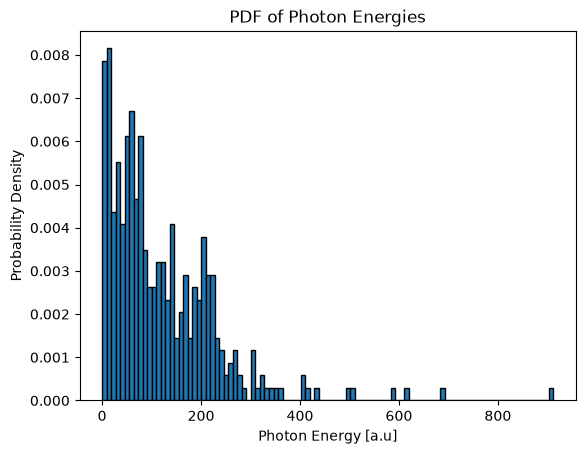

In [55]:
plt.hist(E,bins=100,edgecolor="k",density=True)
plt.xlabel("Photon Energy [a.u]")
plt.ylabel("Probability Density")
plt.title("PDF of Photon Energies")
plt.show()

In [56]:
def signal(ns, E) -> np.array:
    return (ns/N_photons)*cauchy.pdf(E, loc=E0, scale=G)

def background(nb, E) -> np.array:
    return (nb/N_photons)*expon.pdf(E, loc=0, scale=Eb)

def complete_pdf(x, E):
    ns = x
    return signal(ns,E) + background(N_photons - ns,E)

def loglikelihood_total(x, E) -> float:
    return -2*np.sum(np.log(complete_pdf(x,E)), axis=-1)

def loglikelihood_bg(nb,E)->float:
    return -2*np.sum(np.log(background(nb,E)),axis=-1)

def loglikelihood_ratio(x,E):
    return -loglikelihood_total(x,E) + loglikelihood_bg(N_photons,E)

In [57]:
ns_bound = [0,N_photons]
ns_init = N_photons/2
init_vals = [ns_init]
bound_arr = [ns_bound]

In [58]:
min_params = minimize(loglikelihood_total, x0=init_vals, args=E ,method="SLSQP", bounds=bound_arr)
ns = min_params.x.item()
nb = N_photons - ns
print(f"N_signal: {round(ns)} \nN_background:{round(nb)}")

N_signal: 54 
N_background:323


In [59]:
Energy_centers = np.linspace(0,np.max(E),N_photons)
pred_total = complete_pdf(min_params.x,Energy_centers)
pred_signal = signal(ns,Energy_centers)
pred_background = background(nb, Energy_centers)

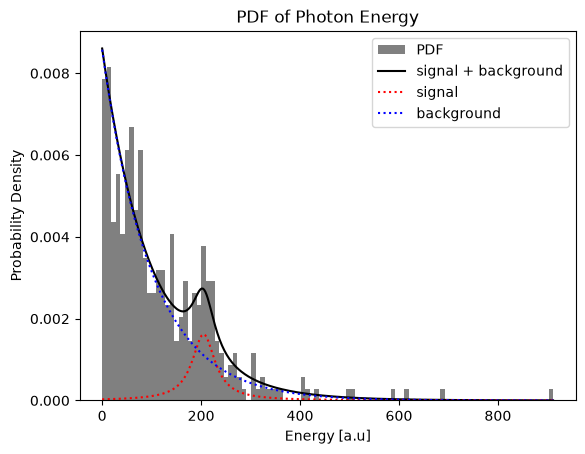

In [60]:
plt.hist(E, bins=100, density=True, label="PDF", color="grey")
plt.plot(Energy_centers, pred_total,color="black", label="signal + background")
plt.plot(Energy_centers, pred_signal,linestyle="dotted",color="red", label="signal")
plt.plot(Energy_centers, pred_background,linestyle="dotted" ,color="blue", label="background")
plt.xlabel("Energy [a.u]")
plt.ylabel("Probability Density")
plt.title("PDF of Photon Energy")
plt.legend()
plt.show()

In [61]:
TS = loglikelihood_ratio(min_params.x,E)
print(f"Test Statistic at best fit : {TS.item() :.3f}")

Test Statistic at best fit : 27.395


In [62]:
N_simul = 10000
E_simulated = np.random.exponential(scale=Eb, size=(N_simul, N_photons))

In [63]:
ns_array = []
for i in range(N_simul):
    E_i = E_simulated[i]
    min_params_i = minimize(loglikelihood_total, x0=init_vals, args=E_i ,method="SLSQP", bounds=bound_arr)
    ns_array.append(min_params_i.x)

In [64]:
ns_array = np.array(ns_array)
ns_array_T = ns_array.reshape(-1,1)

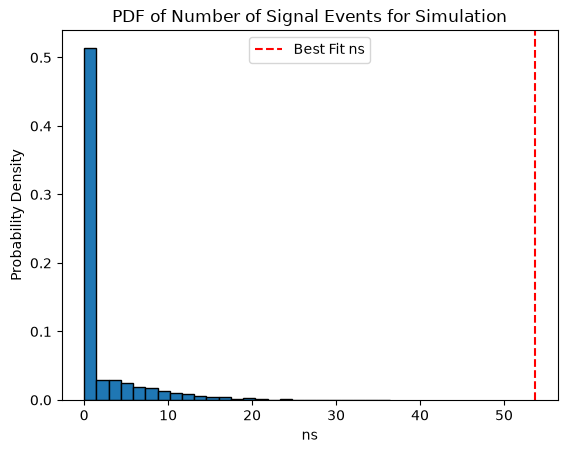

In [65]:
plt.hist(ns_array_T,bins=25,edgecolor="k",density=True)
plt.xlabel("ns")
plt.ylabel("Probability Density")
plt.title("PDF of Number of Signal Events for Simulation")
plt.axvline(x=ns, color='red', linestyle='--', label='Best Fit ns')
plt.legend(loc="upper center")
plt.show()

In [69]:
TS_array = loglikelihood_ratio(ns_array_T, E_simulated)

In [70]:
TS_above = np.percentile(TS_array,99)

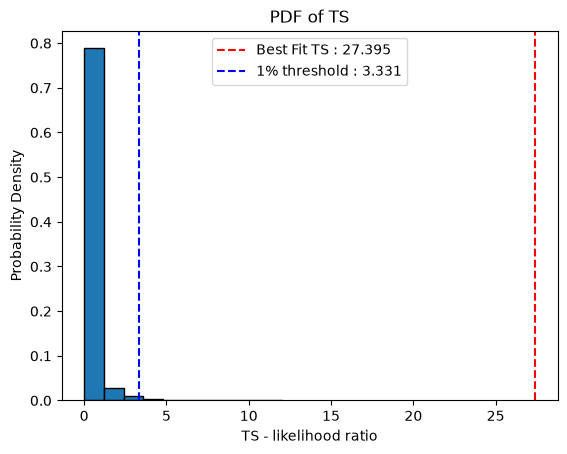

In [75]:
plt.hist(TS_array,bins=10,edgecolor="k",density=True)
plt.xlabel("TS - likelihood ratio")
plt.ylabel("Probability Density")
plt.title("PDF of TS")
plt.axvline(x=TS.item(), color='red', linestyle='--', label=f'Best Fit TS : {TS:.3f}')
plt.axvline(x=TS_above, color='blue', linestyle='--', label=f'1% threshold : {TS_above :.3f}')
plt.legend(loc="upper center")
plt.show()

Yes Null Hypothesis is rejected, the p-value is very large and to the right of the threshold. 

100 would be too statistically limiting, 1e7 would be too computationally expensive